# Tutorial 3: Outliers e Transformação de Dados

**Autor:** Fabio Stein

Este tutorial continua o [Tutorial 1](tutorial_data_wrangling.ipynb) e o [Tutorial 2](tutorial_data_wrangling_parte2.ipynb). Neles você limpou nulos, valores impossíveis, texto bagunçado e duplicados. Aqui você vai aprender a **encontrar e tratar valores atípicos (outliers)**, **corrigir formatos** e **transformar a tabela**: tirar amostras, ordenar, substituir valores, criar faixas e aplicar funções.

**Como usar:** execute uma célula por vez (`Shift + Enter`), leia a explicação antes e olhe o resultado depois. Não pule etapas.

| Parte | Assunto |
|---|---|
| 0 | Preparar o ambiente |
| 1 | Criar e carregar os dados da loja |
| 2 | Formatos e tipos: o dado "camaleão" |
| 3 | Outliers: olhar antes de calcular |
| 4 | Detectar outliers com estatística (IQR, Z-score e MAD) |
| 5 | Outliers em várias dimensões (Isolation Forest) |
| 6 | Tratar outliers: corrigir, marcar, limitar ou transformar |
| 7 | Amostragem e embaralhamento |
| 8 | Ordenação e ranking |
| 9 | Substituir e mapear valores |
| 10 | Faixas de valores: `cut` e `qcut` |
| 11 | Funções com `apply` |
| 12 | Validar e salvar |
| 13 | Exercícios |

## Conceitos fundamentais (leia antes de começar)

### O que é um *outlier*?
Hawkins [1] deu a definição mais citada: um outlier é uma observação que **se afasta tanto das outras** que levanta a suspeita de ter sido **gerada por um mecanismo diferente**. Repare na palavra *suspeita*: um outlier é um **candidato a problema**, não um erro confirmado.

### De onde vêm os outliers?
| Origem | Exemplo | O que fazer |
|---|---|---|
| **Erro** (digitação, unidade, sensor) | preço de R$ 12.990 que era R$ 129,90 (faltou a vírgula) | corrigir, se der para deduzir; senão virar `NaN` |
| **Valor raro, mas legítimo** | uma empresa compra 60 unidades de uma vez | manter e **marcar** |
| **Sinal de algo importante** | compra enorme de madrugada em outro país (fraude?) | **investigar**: muitas vezes é exatamente o que se procura |

### Outlier × valor impossível
No Tutorial 1 (Parte 4) você viu os **valores impossíveis**: eles violam uma regra do mundo real (idade -3). Um **outlier** é diferente: ele é **possível**, só que raro. A estatística serve para **apontar suspeitos**; quem decide o que fazer é o **contexto** e, de preferência, quem conhece o negócio.

### Por que os outliers atrapalham?
A **média** e o **desvio-padrão** não são **robustos**: um único valor absurdo consegue puxá-los para qualquer lugar. Em estatística robusta [2] se diz que a média tem **ponto de ruptura de 0%** (basta um valor ruim para estragá-la), enquanto a **mediana** tem **ponto de ruptura de 50%** (só se estraga quando metade dos dados está ruim). Por isso, neste tutorial, a mediana aparece o tempo todo.

### Como as referências funcionam
Os números entre colchetes, como **[1]**, apontam para a lista de **Referências** no final. Os quadros **📚 Teoria** explicam o conceito por trás de cada passo, e os quadros **🔍 Passo a passo** explicam o código linha a linha.

## Parte 0: Preparar o ambiente

Além das bibliotecas do Tutorial 1, agora usamos o **SciPy** (estatística) e o **scikit-learn** (aprendizado de máquina). Se ainda não tem, rode no terminal:

```
pip install numpy pandas matplotlib seaborn scipy scikit-learn jupyter
```

### 📚 Teoria: as bibliotecas novas
| Biblioteca | Papel neste tutorial | Referência |
|---|---|---|
| **SciPy** | função pronta de Z-score (`stats.zscore`) | Virtanen et al. [3] |
| **scikit-learn** | algoritmo *Isolation Forest* | Pedregosa et al. [4] |

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Tudo pronto! pandas", pd.__version__)

Tudo pronto! pandas 3.1.1


## Parte 1: Criar e carregar os dados da loja

Vamos simular os **pedidos de uma loja virtual** no primeiro semestre. Como no Tutorial 1, geramos um CSV com problemas colocados **de propósito**, para depois conferir se a limpeza encontrou todos.

Não se preocupe em entender esta célula agora. Só execute.

### 🔍 Passo a passo (só para curiosos)
1. `rng.gamma(...)` sorteia preços numa **distribuição gama**: muitos produtos baratos e poucos caros (uma cauda longa à direita, como nos preços reais).
2. `rng.poisson(1.2, n) + 1` sorteia quantidades pequenas (1, 2, 3...), como na maioria das compras.
3. Depois colocamos a "sujeira": compras de empresas (outliers legítimos), preços sem vírgula, prazos negativos, o código 999, preços e datas escritos de jeitos diferentes, e "sim/não" escrito de dez formas.

In [2]:
rng = np.random.default_rng(2026)
n = 400
preco_medio = {"Eletrônicos": 350, "Casa": 120, "Moda": 90, "Livros": 45, "Esporte": 150}

categoria = rng.choice(list(preco_medio), n, p=[0.25, 0.25, 0.20, 0.15, 0.15])
pedidos = pd.DataFrame({
    "pedido_id": range(1, n + 1),
    "data_pedido": pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 181, n), unit="D"),
    "uf": rng.choice(["SP", "RJ", "MG", "PR", "RS", "BA"], n, p=[0.35, 0.20, 0.15, 0.10, 0.10, 0.10]),
    "cliente_tipo": np.where(rng.random(n) < 0.05, "PJ", "PF"),   # PF = pessoa física, PJ = empresa
    "categoria": categoria,
    "quantidade": rng.poisson(1.2, n) + 1,
    "preco_unitario": [round(rng.gamma(4, preco_medio[c] / 4), 2) for c in categoria],
    "desconto_pct": (rng.beta(2, 8, n) * 30).round(1),
    "tempo_entrega_dias": rng.normal(5, 2, n).round().clip(1, None).astype(int),
    "frete_gratis": rng.random(n) < 0.4,
    "avaliacao": rng.choice([1, 2, 3, 4, 5], n, p=[0.05, 0.08, 0.17, 0.35, 0.35]).astype(float),
})

# --- Sujeira proposital ---
# outliers legítimos: compras de empresas (atacado)
atacado = [12, 87, 150, 233, 301, 377]
pedidos.loc[atacado, "cliente_tipo"] = "PJ"
pedidos.loc[atacado, "quantidade"] = [45, 60, 80, 40, 55, 70]
pedidos.loc[atacado, "desconto_pct"] = [35.0, 40.0, 45.0, 35.0, 40.0, 42.0]
# erros: preço digitado sem a vírgula (129,90 virou 12990)
sem_virgula = [25, 140, 260, 333]
# erros: prazo negativo e o código 999 (= "ainda não entregue")
pedidos.loc[[40, 190, 280], "tempo_entrega_dias"] = [-2, -1, -4]
pedidos.loc[[55, 210, 350], "tempo_entrega_dias"] = 999
# nulos comuns
pedidos.loc[rng.choice(n, 25, replace=False), "avaliacao"] = np.nan

# formatos "camaleão"
def preco_em_texto(i, p):
    if i in sem_virgula:
        return str(int(round(p * 100)))
    if rng.random() < 0.25:   # formato brasileiro: R$ 1.299,90
        return "R$ " + f"{p:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{p:.2f}"         # formato "de computador": 1299.90
pedidos["preco_unitario"] = [preco_em_texto(i, p) for i, p in enumerate(pedidos["preco_unitario"])]

datas_br = rng.random(n) < 0.2
pedidos["data_pedido"] = np.where(datas_br,
                                  pedidos["data_pedido"].dt.strftime("%d/%m/%Y"),
                                  pedidos["data_pedido"].dt.strftime("%Y-%m-%d"))
pedidos.loc[[8, 99, 222], "data_pedido"] = ""

sim = ["Sim", "sim", "S", "1", "true"]
nao = ["Não", "nao", "N", "0", "false"]
pedidos["frete_gratis"] = [rng.choice(sim) if f else rng.choice(nao) for f in pedidos["frete_gratis"]]
pedidos.loc[[3, 70, 145], "uf"] = [" sp", "rj ", "Mg"]

pedidos.to_csv("pedidos_loja.csv", index=False)
print("Arquivo 'pedidos_loja.csv' criado!")

Arquivo 'pedidos_loja.csv' criado!


Agora carregamos o arquivo, como faria com qualquer CSV recebido de outro sistema.

In [3]:
df = pd.read_csv("pedidos_loja.csv")
df.head(8)

,pedido_id,data_pedido,uf,cliente_tipo,categoria,quantidade,preco_unitario,desconto_pct,tempo_entrega_dias,frete_gratis,avaliacao
0,1,2026-06-09,RJ,PF,Eletrônicos,4,463.65,1.7,4,nao,3.0
1,2,2026-02-09,PR,PF,Moda,2,76.67,3.2,6,Sim,4.0
2,3,2026-04-26,RJ,PF,Casa,1,49.24,1.7,3,0,2.0
3,4,2026-02-15,sp,PF,Casa,1,110.33,8.0,2,0,5.0
4,5,2026-04-11,RS,PF,Casa,2,97.62,4.2,6,false,2.0
5,6,2026-03-13,RJ,PF,Livros,1,96.52,7.3,8,sim,5.0
6,7,16/06/2026,BA,PF,Esporte,2,146.14,8.0,4,0,NaN
7,8,07/01/2026,SP,PF,Eletrônicos,2,381.62,7.5,1,0,5.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   pedido_id           400 non-null    int64  
 1   data_pedido         397 non-null    str    
 2   uf                  400 non-null    str    
 3   cliente_tipo        400 non-null    str    
 4   categoria           400 non-null    str    
 5   quantidade          400 non-null    int64  
 6   preco_unitario      400 non-null    str    
 7   desconto_pct        400 non-null    float64
 8   tempo_entrega_dias  400 non-null    int64  
 9   frete_gratis        400 non-null    str    
 10  avaliacao           375 non-null    float64
dtypes: float64(2), int64(3), str(6)
memory usage: 34.5 KB


### O que observar no `info()`
- `preco_unitario` deveria ser número, mas veio como **texto** (`object` ou `str`): tem `R$`, vírgulas e pontos misturados.
- `data_pedido` também veio como texto, e tem **3 vazios**.
- `frete_gratis` deveria ser verdadeiro/falso, mas veio como texto.
- `avaliacao` tem nulos (vimos isso no Tutorial 1).

**Antes de procurar outliers, os tipos precisam estar certos.** Não dá para calcular a mediana de um texto.

## Parte 2: Formatos e tipos: o dado "camaleão"

O mesmo dado pode vir escrito de muitas formas: `"1.500"` pode ser mil e quinhentos (Brasil) ou um vírgula cinco (EUA); `03/04/2026` pode ser 3 de abril ou 4 de março. Para o computador, cada forma é um valor diferente.

### 📚 Teoria: formatos causam acidentes de verdade
- Em 1999 a sonda **Mars Climate Orbiter**, da NASA, foi perdida porque uma equipe usava unidades inglesas (libra-força) e outra usava o sistema métrico (newton) [5].
- Ziemann et al. [6] mostraram que cerca de **1 em cada 5** artigos de genética com planilhas anexas tinha nomes de genes convertidos em datas pelo Excel (o gene `SEPT2` virava "2-set").

A lição: **converta cada coluna para o tipo certo, de forma explícita**, e confira quantos valores falharam na conversão.

### 2.1 Preço: texto para número

### 🔍 Passo a passo
1. `.str.strip()` tira os espaços das pontas.
2. `.str.startswith("R$")` marca quais preços estão no formato brasileiro.
3. Nos brasileiros: tiramos o `R$`, apagamos o ponto de milhar e trocamos a vírgula decimal por ponto.
4. `.where(condição, outro)` mantém o valor onde a condição é verdadeira e usa `outro` onde é falsa.
5. `pd.to_numeric(..., errors="coerce")` converte para número; o que não for número vira `NaN` (assim nada passa escondido).

In [5]:
preco_txt = df["preco_unitario"].astype(str).str.strip()
formato_br = preco_txt.str.startswith("R$")
print("Preços no formato brasileiro:", formato_br.sum())
print(preco_txt[formato_br].head(3).tolist())

sem_rs = preco_txt.str.replace("R$", "", regex=False).str.strip()
convertido_br = sem_rs.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
preco_limpo = sem_rs.where(~formato_br, convertido_br)

df["preco_unitario"] = pd.to_numeric(preco_limpo, errors="coerce")
print("Falharam na conversão:", df["preco_unitario"].isna().sum())
df["preco_unitario"].describe().round(2)

Preços no formato brasileiro: 104
['R$ 84,94', 'R$ 52,61', 'R$ 1.020,55']
Falharam na conversão: 0


count      400.00
mean       333.18
std       1792.70
min          9.56
25%         61.03
50%        113.78
75%        198.24
max      23884.00
Name: preco_unitario, dtype: float64

Veja o `max`: um preço na casa das dezenas de milhares numa loja onde a mediana é pouco mais de R$ 100. Esse é o nosso primeiro **suspeito**. Vamos investigá-lo nas Partes 4 e 6.

### 2.2 Datas: dois formatos na mesma coluna

### 📚 Teoria: o padrão ISO 8601
A norma internacional **ISO 8601** [7] escreve datas como `AAAA-MM-DD` (`2026-04-03`). Esse formato não é ambíguo e, quando ordenado como texto, já fica em ordem cronológica. Sempre que puder, guarde datas assim.

### 🔍 Passo a passo
- Não use um palpite automático para datas misturadas: `03/04/2026` seria lido de um jeito ou de outro sem aviso.
- Fazemos **duas conversões explícitas**, uma para cada formato, com `errors="coerce"`.
- `iso.fillna(br)` junta as duas: onde a primeira falhou, usa a segunda.

In [6]:
iso = pd.to_datetime(df["data_pedido"], format="%Y-%m-%d", errors="coerce")
br = pd.to_datetime(df["data_pedido"], format="%d/%m/%Y", errors="coerce")
df["data_pedido"] = iso.fillna(br)

print("Lidas no formato ISO:", iso.notna().sum())
print("Lidas no formato brasileiro:", (iso.isna() & br.notna()).sum())
print("Sem data:", df["data_pedido"].isna().sum())
print("Período:", df["data_pedido"].min().date(), "até", df["data_pedido"].max().date())

Lidas no formato ISO: 308
Lidas no formato brasileiro: 89
Sem data: 3
Período: 2026-01-01 até 2026-06-30


### 2.3 Sim/Não escrito de dez jeitos

### 🔍 Passo a passo
1. `.str.strip().str.lower()` deixa tudo em minúsculas e sem espaços (técnica do Tutorial 1).
2. `.map(dicionario)` troca cada texto pelo valor do dicionário. **Atenção:** o que não estiver no dicionário vira `NaN`. Isso é bom aqui, porque revela grafias que esquecemos.

In [7]:
print("Antes:", sorted(df["frete_gratis"].astype(str).unique()))

para_booleano = {"sim": True, "s": True, "1": True, "true": True,
                 "não": False, "nao": False, "n": False, "0": False, "false": False}
df["frete_gratis"] = df["frete_gratis"].astype(str).str.strip().str.lower().map(para_booleano)

print("Não reconhecidos:", df["frete_gratis"].isna().sum())
df["frete_gratis"].value_counts()

Antes: ['0', '1', 'N', 'Não', 'S', 'Sim', 'false', 'nao', 'sim', 'true']
Não reconhecidos: 0


frete_gratis
False    263
True     137
Name: count, dtype: int64

### 2.4 Siglas de estado

In [8]:
df["uf"] = df["uf"].str.strip().str.upper()
df["uf"].value_counts()

uf
SP    113
RJ     77
MG     62
PR     59
BA     53
RS     36
Name: count, dtype: int64

In [9]:
df.dtypes

pedido_id                      int64
data_pedido           datetime64[us]
uf                               str
cliente_tipo                     str
categoria                        str
quantidade                     int64
preco_unitario               float64
desconto_pct                 float64
tempo_entrega_dias             int64
frete_gratis                    bool
avaliacao                    float64
dtype: object

## Parte 3: Outliers: olhar antes de calcular

**Regra de ouro: um gráfico antes de qualquer fórmula.** O olho humano encontra padrões estranhos muito rápido.

### 📚 Teoria: o boxplot de Tukey
O **boxplot** (diagrama de caixa) foi criado por Tukey [8]. A caixa vai do **1º quartil (Q1)** ao **3º quartil (Q3)**, e a linha do meio é a **mediana**. Os "bigodes" vão até o último ponto que está a no máximo **1,5 × IQR** da caixa (IQR = Q3 − Q1). **Os pontos soltos além dos bigodes são os candidatos a outlier.**

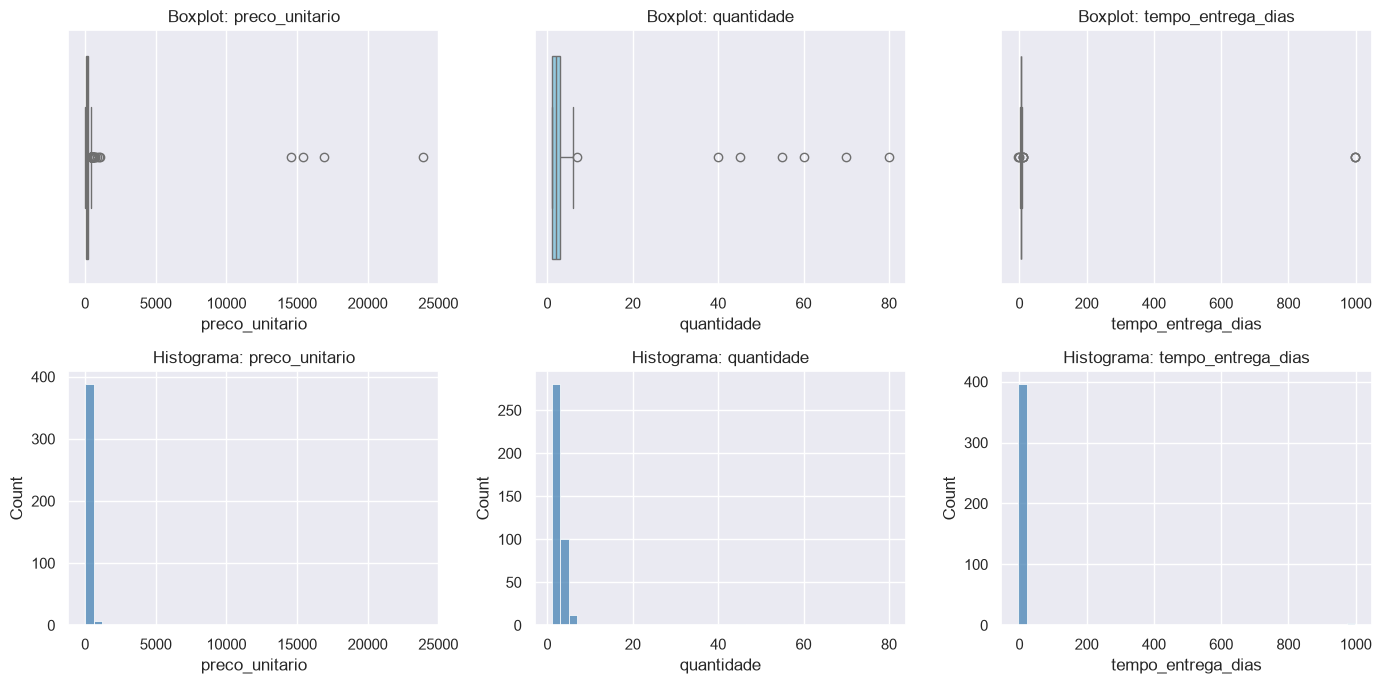

In [10]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 7))
for i, coluna in enumerate(["preco_unitario", "quantidade", "tempo_entrega_dias"]):
    sns.boxplot(x=df[coluna], ax=eixos[0, i], color="skyblue")
    eixos[0, i].set_title(f"Boxplot: {coluna}")
    sns.histplot(df[coluna], bins=40, ax=eixos[1, i], color="steelblue")
    eixos[1, i].set_title(f"Histograma: {coluna}")
plt.tight_layout()
plt.show()

### Como ler os gráficos
- **preco_unitario:** quase tudo está espremido à esquerda, e alguns pontos ficam muito longe. Os pontos muito distantes são os preços sem vírgula.
- **quantidade:** a maioria compra de 1 a 4 unidades; alguns pedidos têm de 40 a 80. São as compras de empresas.
- **tempo_entrega_dias:** a escala vai até 999! O código "ainda não entregue" está distorcendo tudo, e ainda há valores negativos.

### 3.1 O estrago na média

In [11]:
entrega = df["tempo_entrega_dias"]
print(f"Média:   {entrega.mean():6.2f} dias")
print(f"Mediana: {entrega.median():6.2f} dias")
print()
print("Sem os 999:")
print(f"Média:   {entrega[entrega < 999].mean():6.2f} dias")
print(f"Mediana: {entrega[entrega < 999].median():6.2f} dias")

Média:    12.46 dias
Mediana:   5.00 dias

Sem os 999:
Média:     5.00 dias
Mediana:   5.00 dias


Só três valores 999, num total de 400 pedidos, fizeram a média subir vários dias, e a mediana nem se mexeu. Isso é o **ponto de ruptura** da introdução, na prática.

### 3.2 O estrago numa reta de tendência
Outliers também entortam relações entre duas variáveis. Abaixo, uma reta é ajustada aos mesmos dados **sem** e **com** três pontos estranhos.

### 🔍 Passo a passo
- `np.polyfit(x, y, 1)` encontra a reta (grau 1) que melhor passa pelos pontos (**mínimos quadrados**) e devolve a inclinação e o intercepto.
- Como os mínimos quadrados elevam os erros **ao quadrado**, um ponto muito longe pesa muito mais que os outros.

Inclinação sem outliers: 1.94
Inclinação com 3 outliers: 1.32


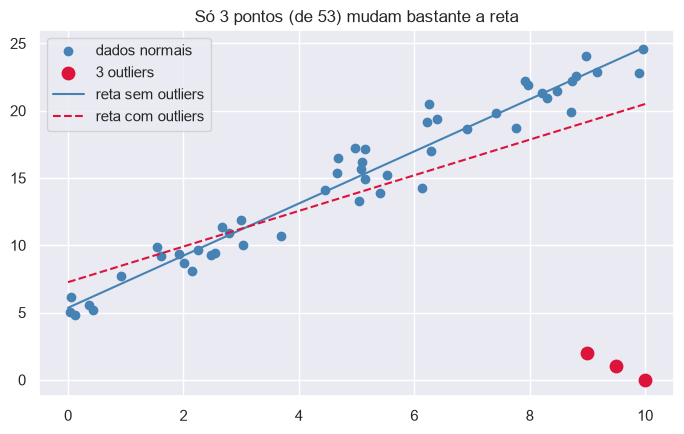

In [12]:
rng_demo = np.random.default_rng(7)
x = rng_demo.uniform(0, 10, 50)
y = 2 * x + 5 + rng_demo.normal(0, 1.5, 50)
x_com = np.append(x, [9.0, 9.5, 10.0])
y_com = np.append(y, [2.0, 1.0, 0.0])

inc_sem, int_sem = np.polyfit(x, y, 1)
inc_com, int_com = np.polyfit(x_com, y_com, 1)
print(f"Inclinação sem outliers: {inc_sem:.2f}")
print(f"Inclinação com 3 outliers: {inc_com:.2f}")

grade = np.linspace(0, 10, 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, color="steelblue", label="dados normais")
plt.scatter([9.0, 9.5, 10.0], [2.0, 1.0, 0.0], color="crimson", s=80, label="3 outliers")
plt.plot(grade, inc_sem * grade + int_sem, color="steelblue", label="reta sem outliers")
plt.plot(grade, inc_com * grade + int_com, color="crimson", linestyle="--", label="reta com outliers")
plt.title("Só 3 pontos (de 53) mudam bastante a reta")
plt.legend()
plt.tight_layout()
plt.show()

## Parte 4: Detectar outliers com estatística (IQR, Z-score e MAD)

O gráfico mostra **que** há algo estranho; uma regra numérica diz **exatamente quais linhas** são suspeitas. Vamos ver as três regras mais usadas e quando cada uma falha.

### 4.1 Regra do IQR (Tukey)

### 📚 Teoria
Você já viu essa regra no Tutorial 1. Ela marca como suspeito o valor fora do intervalo **[Q1 − k·IQR, Q3 + k·IQR]**, com **k = 1,5** para "suspeito" e **k = 3** para "muito suspeito" [8]. Como usa quartis, **não depende da média** e funciona mesmo quando a distribuição não é normal.

### 🔍 Passo a passo
- `serie.quantile([0.25, 0.75])` calcula Q1 e Q3 de uma vez.
- A função devolve os limites para reutilizarmos em outras colunas.

In [13]:
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for coluna in ["preco_unitario", "quantidade", "tempo_entrega_dias", "desconto_pct"]:
    inferior, superior = limites_iqr(df[coluna])
    fora = df[(df[coluna] < inferior) | (df[coluna] > superior)]
    print(f"{coluna:20s} limites [{inferior:8.2f}, {superior:8.2f}]  suspeitos: {len(fora)}")

preco_unitario       limites [ -144.79,   404.06]  suspeitos: 31
quantidade           limites [   -2.00,     6.00]  suspeitos: 7
tempo_entrega_dias   limites [    1.00,     9.00]  suspeitos: 10
desconto_pct         limites [   -4.44,    15.66]  suspeitos: 13


### 4.2 Z-score

### 📚 Teoria
O **Z-score** mede a quantos desvios-padrão um valor está da média: **z = (x − média) / desvio-padrão**. A regra clássica marca como outlier o valor com **|z| > 3**: numa distribuição normal, só 0,3% dos dados ficam tão longe.

O problema: média e desvio-padrão **são estragados pelos próprios outliers** que queremos achar. O outlier aumenta o desvio-padrão e assim **se esconde**. Isso se chama **efeito de mascaramento** [9]. Pior: Shiffler [10] provou que, numa amostra de tamanho *n*, o maior |z| possível é **(n − 1) / √n**. Com 9 valores, esse máximo é 2,67, ou seja, **nenhum valor consegue passar de 3**, por mais absurdo que seja.

In [14]:
amostra = pd.Series([10, 11, 12, 11, 10, 12, 11, 95, 98])   # 95 e 98 são claramente estranhos
z = (amostra - amostra.mean()) / amostra.std(ddof=0)
print(pd.DataFrame({"valor": amostra, "z": z.round(2)}).T)
print()
print("Maior |z| possível com n = 9:", round((9 - 1) / np.sqrt(9), 2))
print("Algum |z| > 3?", (z.abs() > 3).any())

           0      1      2      3      4      5      6      7      8
valor  10.00  11.00  12.00  11.00  10.00  12.00  11.00  95.00  98.00
z      -0.56  -0.53  -0.51  -0.53  -0.56  -0.51  -0.53   1.83   1.91

Maior |z| possível com n = 9: 2.67
Algum |z| > 3? False


O `stats.zscore` do SciPy faz a mesma conta. Na coluna de prazos (com 400 linhas), o Z-score funciona melhor, porque há muitos dados "normais" para segurar a média:

In [15]:
z_entrega = np.abs(stats.zscore(df["tempo_entrega_dias"]))
df.loc[z_entrega > 3, ["pedido_id", "tempo_entrega_dias"]]

,pedido_id,tempo_entrega_dias
55,56,999
210,211,999
350,351,999


Repare: o Z-score achou os 999, mas **não achou os prazos negativos**. Os 999 inflaram tanto o desvio-padrão que -4 dias parece "normal". É o mascaramento de novo.

### 4.3 MAD: o Z-score robusto

### 📚 Teoria
A solução é trocar a média pela **mediana** e o desvio-padrão pelo **MAD** (*median absolute deviation*, desvio absoluto mediano) [9][11]:

- **MAD = mediana( |x − mediana(x)| )**
- **z modificado = 0,6745 × (x − mediana) / MAD**
- Iglewicz e Hoaglin [9] recomendam marcar como outlier o valor com **|z modificado| > 3,5**.

O 0,6745 ajusta a escala para o z modificado valer o mesmo que o z comum quando os dados são normais. Leys et al. [11] defendem que o MAD deveria ser o padrão em pesquisas.

**Cuidado:** se mais da metade dos valores for igual, o MAD dá 0 e a divisão explode. Nesse caso use o IQR.

In [16]:
def z_modificado(serie):
    mediana = serie.median()
    mad = (serie - mediana).abs().median()
    if mad == 0:
        raise ValueError("MAD = 0: mais da metade dos valores é igual. Use o IQR.")
    return 0.6745 * (serie - mediana) / mad

zm = z_modificado(amostra)
print(pd.DataFrame({"valor": amostra, "z_modificado": zm.round(2)}).T)
print()
print("Outliers pelo MAD:", amostra[zm.abs() > 3.5].tolist())

                  0     1      2     3      4      5     6      7      8
valor         10.00  11.0  12.00  11.0  10.00  12.00  11.0  95.00  98.00
z_modificado  -0.67   0.0   0.67   0.0  -0.67   0.67   0.0  56.66  58.68

Outliers pelo MAD: [95, 98]


In [17]:
zm_entrega = z_modificado(df["tempo_entrega_dias"])
df.loc[zm_entrega.abs() > 3.5, ["pedido_id", "tempo_entrega_dias"]].sort_values("tempo_entrega_dias")

,pedido_id,tempo_entrega_dias
280,281,-4
40,41,-2
190,191,-1
76,77,11
287,288,11
55,56,999
210,211,999
350,351,999


Agora os prazos negativos **e** os 999 apareceram. Também apareceram dois pedidos de 11 dias: são **atrasos possíveis**, não erros. A regra aponta suspeitos; quem decide é você (na Parte 6 eles ficam como estão).

### 4.4 Comparando as três regras numa coluna assimétrica
Preços têm **cauda longa à direita** (muitos baratos, poucos caros). Veja quantos suspeitos cada regra aponta:

In [18]:
preco = df["preco_unitario"]
inf_iqr, sup_iqr = limites_iqr(preco)
comparacao = pd.Series({
    "IQR (k=1,5)": ((preco < inf_iqr) | (preco > sup_iqr)).sum(),
    "IQR (k=3)": ((preco < limites_iqr(preco, 3)[0]) | (preco > limites_iqr(preco, 3)[1])).sum(),
    "Z-score (|z|>3)": (np.abs(stats.zscore(preco)) > 3).sum(),
    "MAD (|z_mod|>3,5)": (z_modificado(preco).abs() > 3.5).sum(),
}, name="suspeitos")
comparacao

IQR (k=1,5)          31
IQR (k=3)            11
Z-score (|z|>3)       4
MAD (|z_mod|>3,5)    27
Name: suspeitos, dtype: int64

### Como interpretar
- As regras **discordam**, e isso é normal: cada uma faz uma suposição diferente sobre os dados.
- Numa distribuição assimétrica, o IQR com k = 1,5 marca muitos produtos **caros, mas legítimos** (um notebook custa mesmo bem mais que um livro).
- **Comparar laranjas com bananas** atrapalha: o "normal" de Eletrônicos é diferente do "normal" de Livros.

### 4.5 Detectar dentro de cada grupo
A saída é aplicar a regra **por categoria**. O `groupby(...).transform(...)` (visto no Tutorial 1) calcula os limites de cada grupo e devolve uma coluna do mesmo tamanho da tabela.

### 🔍 Passo a passo
- `transform(lambda s: limites_iqr(s, 3)[1])` calcula o limite superior (k = 3, bem rigoroso) **de cada categoria**.
- Comparamos cada preço com o limite **da sua própria categoria**.

In [19]:
por_categoria = df.groupby("categoria")["preco_unitario"]
df["limite_sup_categoria"] = por_categoria.transform(lambda s: limites_iqr(s, 3)[1])
suspeitos = df[df["preco_unitario"] > df["limite_sup_categoria"]]
suspeitos[["pedido_id", "categoria", "preco_unitario", "limite_sup_categoria"]].round(2)

,pedido_id,categoria,preco_unitario,limite_sup_categoria
25,26,Casa,14592.0,427.08
140,141,Moda,16933.0,335.89
260,261,Esporte,15443.0,480.71
333,334,Moda,23884.0,335.89


Agora a lista é curta e certeira: são preços **muito acima do normal da própria categoria**. Na Parte 6 vamos verificar se eles são os preços sem vírgula.

## Parte 5: Outliers em várias dimensões (Isolation Forest)

Às vezes cada valor, sozinho, é normal, mas a **combinação** é estranha. Uma pessoa de 23 anos é normal. Alguém com 18 anos de experiência profissional também. Uma pessoa de 23 anos **com** 18 anos de experiência, não.

### 📚 Teoria: isolar é mais fácil que descrever
O **Isolation Forest** [12] parte de uma ideia simples: anomalias são **poucas e diferentes**, então são **fáceis de isolar**. O algoritmo corta os dados ao acaso, várias vezes, até cada ponto ficar sozinho. Um ponto normal, no meio da multidão, precisa de muitos cortes; um ponto anômalo fica sozinho com poucos cortes. A média de cortes em muitas árvores aleatórias vira uma **nota de anomalia**.

- `contamination`: a fração de dados que você **espera** que seja anômala (é um palpite seu, não uma descoberta do algoritmo).
- `fit_predict` devolve **1** para normal e **-1** para anomalia.
- Ele é **não supervisionado**: não precisa de exemplos rotulados de "fraude" ou "erro".

### 5.1 Exemplo com duas variáveis

In [20]:
rng_rh = np.random.default_rng(11)
idade = rng_rh.integers(22, 61, 300)
experiencia = (idade - 22 + rng_rh.normal(0, 2, 300)).clip(0).round()
rh = pd.DataFrame({"idade": idade, "experiencia": experiencia})
rh.loc[len(rh)] = [23, 18]    # combinação impossível
rh.loc[len(rh)] = [26, 21]    # combinação impossível

# A regra do IQR, coluna por coluna, não vê nada de errado:
for coluna in ["idade", "experiencia"]:
    inferior, superior = limites_iqr(rh[coluna])
    print(coluna, "fora do IQR:", ((rh[coluna] < inferior) | (rh[coluna] > superior)).sum())

modelo = IsolationForest(contamination=0.01, random_state=42)
rh["anomalia"] = modelo.fit_predict(rh[["idade", "experiencia"]]) == -1
rh[rh["anomalia"]]

idade fora do IQR: 0
experiencia fora do IQR: 0


,idade,experiencia,anomalia
48,60,42.0,True
163,60,41.0,True
300,23,18.0,True
301,26,21.0,True


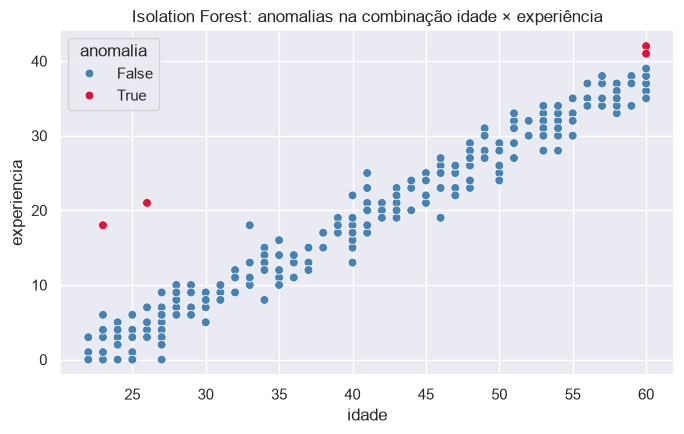

In [21]:
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=rh, x="idade", y="experiencia", hue="anomalia",
                palette={False: "steelblue", True: "crimson"}, s=40)
plt.title("Isolation Forest: anomalias na combinação idade × experiência")
plt.tight_layout()
plt.show()

### Como interpretar
- As duas combinações impossíveis (23 anos com 18 de experiência e 26 com 21) foram encontradas, e a regra do IQR, coluna por coluna, não tinha visto nenhuma.
- O algoritmo também marcou duas pessoas de 60 anos com 41 e 42 anos de experiência. Elas estão na **ponta da nuvem**: são raras, mas possíveis. Como pedimos `contamination=0.01` (1% de 302 linhas), ele **precisava** apontar cerca de 3 ou 4 linhas.

### 5.2 Nos pedidos da loja
Vamos olhar três colunas ao mesmo tempo: quantidade, preço e desconto.

In [22]:
colunas = ["quantidade", "preco_unitario", "desconto_pct"]
modelo = IsolationForest(contamination=0.03, random_state=42)
df["anomalia_if"] = modelo.fit_predict(df[colunas]) == -1
df["nota_anomalia"] = -modelo.score_samples(df[colunas])   # quanto maior, mais estranho

(df[df["anomalia_if"]]
 .sort_values("nota_anomalia", ascending=False)
 [["pedido_id", "cliente_tipo", "categoria"] + colunas + ["nota_anomalia"]]
 .round(2))

,pedido_id,cliente_tipo,categoria,quantidade,preco_unitario,desconto_pct,nota_anomalia
150,151,PJ,Esporte,80,108.88,45.0,0.80
377,378,PJ,Casa,70,155.92,42.0,0.78
333,334,PF,Moda,2,23884.00,7.2,0.77
87,88,PJ,Moda,60,60.03,40.0,0.76
301,302,PJ,Casa,55,177.80,40.0,0.76
12,13,PJ,Moda,45,84.94,35.0,0.75
233,234,PJ,Moda,40,106.31,35.0,0.75
25,26,PF,Casa,3,14592.00,6.5,0.73
140,141,PF,Moda,1,16933.00,1.7,0.73
260,261,PF,Esporte,2,15443.00,1.8,0.72


### Como interpretar
- O algoritmo apontou as **compras de empresas** (PJ, quantidade alta, desconto alto) e os **preços sem vírgula**. No fim da lista aparecem pedidos comuns, com quantidade e desconto só um pouco acima do normal: é o `contamination=0.03` obrigando o modelo a completar 3% das linhas.
- **Ele não sabe** que compra de empresa é legítima e preço sem vírgula é erro. Essa decisão é sua, com a ajuda de quem conhece o negócio.
- Isolation Forest é ótimo para **gerar uma lista curta para investigar**, não para apagar linhas automaticamente.

## Parte 6: Tratar outliers: corrigir, marcar, limitar ou transformar

Não existe "o" tratamento de outliers. Há quatro opções, e a escolha depende da **origem** do valor:

| Situação | Ação | Exemplo neste tutorial |
|---|---|---|
| Erro com correção óbvia | **corrigir** | preço sem vírgula ÷ 100 |
| Erro sem correção possível, ou código especial | **virar `NaN`** | prazo negativo, código 999 |
| Valor legítimo e importante | **manter e marcar** | compra de empresa |
| Valor legítimo que atrapalha um cálculo | **limitar** (winsorizar) ou **transformar** (log) | valor total do pedido |

**Regra de ouro: nunca apague um outlier sem perguntar por que ele existe.** E trabalhe sempre numa cópia, guardando o original.

### 6.1 Corrigir: preço sem vírgula

### 🔍 Passo a passo
1. Pegamos os preços acima do limite rigoroso (k = 3) da própria categoria (Parte 4.5).
2. Testamos a hipótese "faltou a vírgula": dividido por 100, o preço fica entre R$ 1 e esse mesmo limite da categoria?
3. Só corrigimos quando a resposta é **sim**. Se não fosse, o valor iria para revisão manual.

Por que não exigir que o preço corrigido caia na faixa "normal" (k = 1,5)? Porque um produto **caro, mas legítimo** pode ficar um pouco acima dela. Uma primeira versão deste tutorial fez isso e deixou um preço sem vírgula passar. Quem pegou o erro foi a validação da Parte 12: por isso ela existe.

In [23]:
df_original = df.copy()   # guardamos a versão antes do tratamento

dividido = df["preco_unitario"] / 100

acima = df["preco_unitario"] > df["limite_sup_categoria"]
faz_sentido = dividido.between(1, df["limite_sup_categoria"])
corrigir = acima & faz_sentido

df.loc[corrigir, "preco_unitario"] = dividido[corrigir]
print("Preços corrigidos:", corrigir.sum())
print("Acima do limite sem explicação (revisar à mão):", (acima & ~faz_sentido).sum())
pd.DataFrame({"antes": df_original.loc[corrigir, "preco_unitario"],
              "depois": df.loc[corrigir, "preco_unitario"],
              "categoria": df.loc[corrigir, "categoria"]})

Preços corrigidos: 4
Acima do limite sem explicação (revisar à mão): 0


,antes,depois,categoria
25,14592.0,145.92,Casa
140,16933.0,169.33,Moda
260,15443.0,154.43,Esporte
333,23884.0,238.84,Moda


### 6.2 Virar `NaN`: prazo negativo e código 999
O 999 não é um prazo: é um **nulo disfarçado** (Tutorial 1, Parte 3) que significa "ainda não entregue". Já o prazo negativo é impossível. Nenhum dos dois pode ser corrigido com segurança, então viram `NaN`.

Antes, guardamos a informação numa coluna própria: "ainda não entregue" é um fato útil sobre o pedido.

In [24]:
df["nao_entregue"] = df["tempo_entrega_dias"] == 999
invalido = (df["tempo_entrega_dias"] < 0) | df["nao_entregue"]
df["tempo_entrega_dias"] = df["tempo_entrega_dias"].mask(invalido)   # mask: vira NaN onde a condição é verdadeira

print("Viraram NaN:", invalido.sum())
df["tempo_entrega_dias"].describe().round(2)

Viraram NaN: 6


count    394.00
mean       5.06
std        1.89
min        1.00
25%        4.00
50%        5.00
75%        6.00
max       11.00
Name: tempo_entrega_dias, dtype: float64

### 6.3 Manter e marcar: compras de empresas
As compras grandes são **reais** e importantes (podem ser os melhores clientes!). Apagá-las seria jogar fora informação. Criamos uma coluna que as identifica, e cada análise decide se as inclui ou não.

In [25]:
_, sup_qtd = limites_iqr(df["quantidade"], k=3)
df["pedido_atacado"] = df["quantidade"] > sup_qtd
print("Limite de quantidade (k=3):", sup_qtd)
df.loc[df["pedido_atacado"], ["pedido_id", "cliente_tipo", "quantidade", "desconto_pct"]]

Limite de quantidade (k=3): 9.0


,pedido_id,cliente_tipo,quantidade,desconto_pct
12,13,PJ,45,35.0
87,88,PJ,60,40.0
150,151,PJ,80,45.0
233,234,PJ,40,35.0
301,302,PJ,55,40.0
377,378,PJ,70,42.0


Com os preços já corrigidos, calculamos o **valor total** de cada pedido:

In [26]:
df["valor_total"] = (df["quantidade"] * df["preco_unitario"] * (1 - df["desconto_pct"] / 100)).round(2)
df["valor_total"].describe().round(2)

count     400.00
mean      387.01
std       621.41
min        10.06
25%        93.48
50%       189.16
75%       427.81
max      6330.35
Name: valor_total, dtype: float64

### 6.4 Limitar: winsorização

### 📚 Teoria
**Winsorizar** é trocar os valores das pontas pelo valor de um percentil: tudo acima do percentil 99 vira o próprio percentil 99, e tudo abaixo do percentil 1 vira o percentil 1. É diferente de **apagar** (aparar, *trimming*): a linha continua lá, só que com um valor menos extremo. É uma técnica clássica da estatística robusta [13].

Use quando um cálculo sensível (média, desvio-padrão, regressão) precisa ficar estável. **Guarde a coluna original**: o valor verdadeiro ainda importa para outras perguntas, como o faturamento total.

### 🔍 Passo a passo
- `quantile([0.01, 0.99])` calcula os dois percentis.
- `.clip(lower, upper)` corta tudo o que passa desses limites.

In [27]:
p01, p99 = df["valor_total"].quantile([0.01, 0.99])
df["valor_total_wins"] = df["valor_total"].clip(p01, p99)

print(f"Limites: R$ {p01:.2f} e R$ {p99:.2f}")
print(f"Média original:     R$ {df['valor_total'].mean():9.2f}")
print(f"Média winsorizada:  R$ {df['valor_total_wins'].mean():9.2f}")
print(f"Mediana (não muda): R$ {df['valor_total'].median():9.2f}")

Limites: R$ 23.11 e R$ 2487.30
Média original:     R$    387.01
Média winsorizada:  R$    362.58
Mediana (não muda): R$    189.16


### 6.5 Transformar: escala logarítmica

### 📚 Teoria
Em dados com cauda longa à direita (preços, rendas, tempos), muitos "outliers" são apenas a cauda natural. O **logaritmo** comprime os valores grandes e estica os pequenos, e a distribuição fica mais simétrica. A transformação log é um caso particular da família de **Box-Cox** [14].

- `np.log1p(x)` calcula **log(1 + x)**, que funciona mesmo quando x = 0.
- A volta é `np.expm1(y)`.

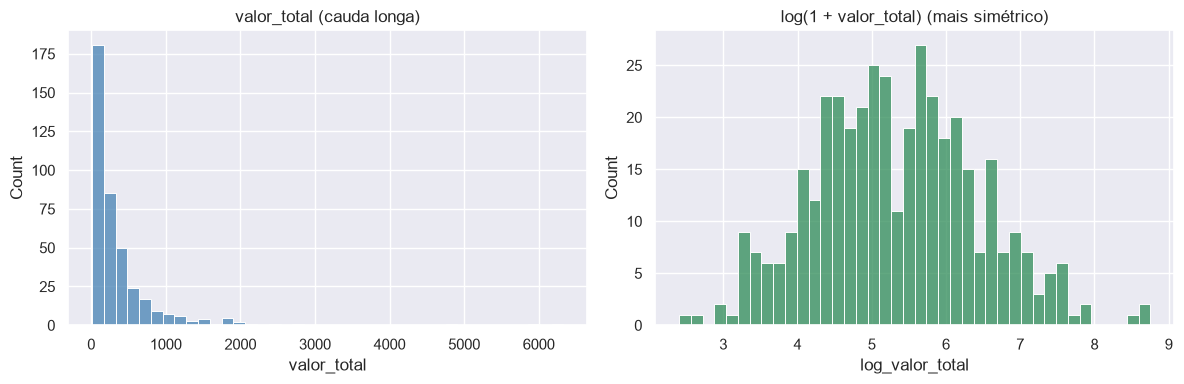

Suspeitos pelo IQR em valor_total: 38
Suspeitos pelo IQR em log_valor_total: 3


In [28]:
df["log_valor_total"] = np.log1p(df["valor_total"])

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["valor_total"], bins=40, ax=eixos[0], color="steelblue")
eixos[0].set_title("valor_total (cauda longa)")
sns.histplot(df["log_valor_total"], bins=40, ax=eixos[1], color="seagreen")
eixos[1].set_title("log(1 + valor_total) (mais simétrico)")
plt.tight_layout()
plt.show()

for coluna in ["valor_total", "log_valor_total"]:
    inferior, superior = limites_iqr(df[coluna])
    print(f"Suspeitos pelo IQR em {coluna}: {((df[coluna] < inferior) | (df[coluna] > superior)).sum()}")

Na escala log, quase todos os "suspeitos" desaparecem: eles eram apenas a **cauda natural** dos valores, não erros. Os 3 que sobram são as três maiores compras de empresas.

## Parte 7: Amostragem e embaralhamento

Uma **amostra** é um pedaço da tabela. Ela serve para testar código rápido numa base gigante, para separar dados de treino e de teste, e para estimar incertezas.

### 📚 Teoria: amostra aleatória simples × estratificada
Na **amostra aleatória simples**, toda linha tem a mesma chance de ser sorteada. Na **amostra estratificada**, você divide a tabela em grupos (**estratos**), por exemplo por estado, e sorteia **dentro de cada grupo**. Assim cada grupo aparece na amostra na mesma proporção da tabela inteira [15]. Isso importa quando há grupos pequenos, que a amostra simples pode deixar de fora por azar.

### 7.1 Amostra simples

### 🔍 Passo a passo
- `sample(n=5)`: sorteia 5 linhas. `sample(frac=0.1)`: sorteia 10% das linhas.
- `random_state=1` fixa a semente: o mesmo sorteio toda vez (**reprodutibilidade**, como no Tutorial 1).

In [29]:
df.sample(n=5, random_state=1)[["pedido_id", "uf", "categoria", "valor_total"]]

,pedido_id,uf,categoria,valor_total
398,399,SP,Moda,265.92
125,126,RS,Eletrônicos,1895.39
328,329,MG,Esporte,75.13
339,340,RJ,Esporte,211.55
172,173,MG,Moda,46.54


In [30]:
amostra_10 = df.sample(frac=0.1, random_state=1)
print("Linhas na amostra de 10%:", len(amostra_10))

Linhas na amostra de 10%: 40


### 7.2 Amostra estratificada
`groupby("uf").sample(frac=0.2)` sorteia 20% **de cada estado**. Compare as proporções:

In [31]:
simples = df.sample(frac=0.2, random_state=3)
estratificada = df.groupby("uf").sample(frac=0.2, random_state=3)

pd.DataFrame({
    "tabela inteira": df["uf"].value_counts(normalize=True),
    "amostra simples": simples["uf"].value_counts(normalize=True),
    "estratificada": estratificada["uf"].value_counts(normalize=True),
}).round(3)

,tabela inteira,amostra simples,estratificada
uf,,,
BA,0.132,0.138,0.138
MG,0.155,0.162,0.150
PR,0.148,0.162,0.150
RJ,0.192,0.200,0.188
RS,0.090,0.088,0.088
SP,0.282,0.250,0.288


A estratificada fica praticamente igual à tabela inteira; a simples oscila mais.

### 7.3 Amostra com reposição: o *bootstrap*

### 📚 Teoria
Com `replace=True`, uma linha sorteada **volta para o sorteio** e pode sair de novo. Efron [16] percebeu que repetir esse sorteio milhares de vezes, sempre do mesmo tamanho da tabela, imita o que aconteceria se coletássemos **novas amostras** da população. Esse é o **bootstrap**: a variação das médias dessas reamostras mostra **o quanto podemos confiar** na média calculada.

### 🔍 Passo a passo
1. Repetimos 2.000 vezes: sorteamos 400 pedidos com reposição e guardamos a média de `valor_total`.
2. Os percentis 2,5% e 97,5% dessas médias formam um **intervalo de confiança de 95%**.

Média observada: R$ 387.01
Intervalo de confiança de 95%: R$ 333.31 a R$ 448.85


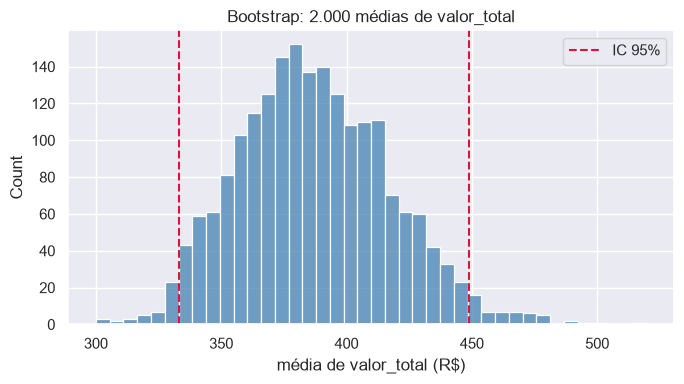

In [32]:
medias = [df["valor_total"].sample(frac=1, replace=True, random_state=i).mean() for i in range(2000)]
medias = pd.Series(medias)
ic_inf, ic_sup = medias.quantile([0.025, 0.975])

print(f"Média observada: R$ {df['valor_total'].mean():.2f}")
print(f"Intervalo de confiança de 95%: R$ {ic_inf:.2f} a R$ {ic_sup:.2f}")

plt.figure(figsize=(7, 4))
sns.histplot(medias, bins=40, color="steelblue")
plt.axvline(ic_inf, color="crimson", linestyle="--", label="IC 95%")
plt.axvline(ic_sup, color="crimson", linestyle="--")
plt.title("Bootstrap: 2.000 médias de valor_total")
plt.xlabel("média de valor_total (R$)")
plt.legend()
plt.tight_layout()
plt.show()

### 7.4 Embaralhar a tabela
`sample(frac=1)` sorteia **100% das linhas**, ou seja, devolve a tabela inteira em **ordem aleatória**. É o que se faz antes de dividir em treino e teste, para não pegar, por exemplo, só os pedidos de janeiro no treino. `reset_index(drop=True)` renumera as linhas de 0 em diante.

In [33]:
embaralhado = df.sample(frac=1, random_state=42)
print("Índices depois de embaralhar:", embaralhado.index[:8].tolist())
embaralhado = embaralhado.reset_index(drop=True)
print("Depois do reset_index:     ", embaralhado.index[:8].tolist())

Índices depois de embaralhar: [209, 280, 33, 210, 93, 84, 329, 94]
Depois do reset_index:      [0, 1, 2, 3, 4, 5, 6, 7]


### 7.5 Embaralhar uma coluna só (teste de permutação)

### 📚 Teoria
Se embaralharmos **apenas uma coluna**, quebramos qualquer relação dela com as outras. Se a relação some depois de embaralhar, ela era real; se continuasse parecida, era acaso. Essa é a ideia dos **testes de permutação** [17].

In [34]:
rng_perm = np.random.default_rng(5)
quantidade_embaralhada = rng_perm.permutation(df["quantidade"].to_numpy())

print("Correlação quantidade × valor_total:", round(df["quantidade"].corr(df["valor_total"]), 3))
print("Depois de embaralhar a quantidade:   ",
      round(pd.Series(quantidade_embaralhada).corr(df["valor_total"]), 3))

Correlação quantidade × valor_total: 0.793
Depois de embaralhar a quantidade:    0.094


## Parte 8: Ordenação e ranking

### 🔍 Os principais parâmetros de `sort_values`
- `by`: a coluna (ou lista de colunas) usada para ordenar.
- `ascending`: `True` (crescente, o padrão) ou `False` (decrescente). Com várias colunas, aceita uma lista, uma direção para cada.
- `na_position`: onde ficam os `NaN`: `"last"` (padrão) ou `"first"`.

### 8.1 Ordenar por uma e por várias colunas

In [35]:
df.sort_values("valor_total", ascending=False)[["pedido_id", "categoria", "valor_total"]].head()

,pedido_id,categoria,valor_total
377,378,Casa,6330.35
301,302,Casa,5867.40
150,151,Esporte,4790.72
233,234,Moda,2764.06
12,13,Moda,2484.50


In [36]:
# Categoria em ordem alfabética e, dentro de cada uma, do maior para o menor valor
(df.sort_values(["categoria", "valor_total"], ascending=[True, False])
   [["categoria", "pedido_id", "valor_total"]]
   .head(8))

,categoria,pedido_id,valor_total
377,Casa,378,6330.35
301,Casa,302,5867.40
274,Casa,275,1520.74
192,Casa,193,1120.95
61,Casa,62,948.93
51,Casa,52,625.85
326,Casa,327,596.44
385,Casa,386,583.83


In [37]:
# Onde ficam os pedidos sem avaliação?
df.sort_values("avaliacao", na_position="first")[["pedido_id", "avaliacao"]].head(4)

,pedido_id,avaliacao
6,7,NaN
28,29,NaN
32,33,NaN
37,38,NaN


### 8.2 Voltar para a ordem original
Depois de embaralhar ou ordenar, `sort_index()` devolve as linhas à ordem do índice.

In [38]:
print(embaralhado.sample(frac=1, random_state=0).sort_index().index[:8].tolist())

[0, 1, 2, 3, 4, 5, 6, 7]


### 8.3 Os maiores e os menores
`nlargest(n, coluna)` e `nsmallest(n, coluna)` são atalhos mais rápidos que ordenar a tabela inteira para pegar só o topo.

In [39]:
df.nlargest(3, "valor_total")[["pedido_id", "cliente_tipo", "quantidade", "valor_total"]]

,pedido_id,cliente_tipo,quantidade,valor_total
377,378,PJ,70,6330.35
301,302,PJ,55,5867.40
150,151,PJ,80,4790.72


### 8.4 Ranking e empates

### 🔍 Passo a passo
`rank` dá a **posição** de cada valor. A diferença entre os métodos aparece nos **empates**:
- `method="min"`: empatados recebem a menor posição, e a próxima posição é pulada (1, 2, 2, 4), como numa competição esportiva.
- `method="dense"`: empatados recebem a mesma posição, sem pular (1, 2, 2, 3).
- `method="first"`: desempata pela ordem em que aparecem (1, 2, 3, 4).

In [40]:
notas = pd.Series([9.5, 8.0, 8.0, 7.0], index=["Ana", "Bia", "Caio", "Davi"])
pd.DataFrame({
    "nota": notas,
    "min": notas.rank(ascending=False, method="min"),
    "dense": notas.rank(ascending=False, method="dense"),
    "first": notas.rank(ascending=False, method="first"),
})

,nota,min,dense,first
Ana,9.5,1.0,1.0,1.0
Bia,8.0,2.0,2.0,2.0
Caio,8.0,2.0,2.0,3.0
Davi,7.0,4.0,3.0,4.0


### 8.5 Os 2 maiores pedidos de cada categoria
Duas formas: ordenar e pegar o começo de cada grupo com `groupby(...).head(2)`, ou calcular o ranking **dentro do grupo**.

In [41]:
top2 = (df.sort_values("valor_total", ascending=False)
          .groupby("categoria")
          .head(2)
          .sort_values(["categoria", "valor_total"], ascending=[True, False]))
top2[["categoria", "pedido_id", "valor_total"]]

,categoria,pedido_id,valor_total
377,Casa,378,6330.35
301,Casa,302,5867.40
170,Eletrônicos,171,1979.02
19,Eletrônicos,20,1934.96
150,Esporte,151,4790.72
183,Esporte,184,956.12
397,Livros,398,239.72
159,Livros,160,174.69
233,Moda,234,2764.06
12,Moda,13,2484.50


In [42]:
df["ranking_na_categoria"] = df.groupby("categoria")["valor_total"].rank(ascending=False, method="first")
df[df["ranking_na_categoria"] <= 2].shape

(10, 20)

## Parte 9: Substituir e mapear valores

### 📚 Teoria: `replace` × `map`
Os dois trocam valores usando um dicionário, mas tratam de jeito diferente o que **não está** no dicionário:

| Método | Valor fora do dicionário | Quando usar |
|---|---|---|
| `replace` | **continua igual** | trocar só alguns valores e manter o resto |
| `map` | **vira `NaN`** | traduzir **todos** os valores (e descobrir os que faltaram) |

### 9.1 Vendo a diferença na prática

In [43]:
regiao = {"SP": "Sudeste", "RJ": "Sudeste", "MG": "Sudeste", "PR": "Sul", "RS": "Sul"}   # esquecemos a BA!

comparacao = pd.DataFrame({
    "uf": df["uf"],
    "com_replace": df["uf"].replace(regiao),
    "com_map": df["uf"].map(regiao),
})
comparacao[comparacao["uf"] == "BA"].head(3)

,uf,com_replace,com_map
6,BA,BA,NaN
10,BA,BA,NaN
28,BA,BA,NaN


Com `replace`, a BA passou sem aviso (e "BA" não é uma região!). Com `map`, apareceu `NaN`, e o erro fica fácil de achar. Corrigimos o dicionário:

In [44]:
regiao["BA"] = "Nordeste"
df["regiao"] = df["uf"].map(regiao)
assert df["regiao"].notna().all(), "Ainda há UF sem região!"
df["regiao"].value_counts()

regiao
Sudeste     252
Sul          95
Nordeste     53
Name: count, dtype: int64

### 9.2 Substituir com condição
- `df.loc[condição, "coluna"] = valor` muda só as linhas onde a condição é verdadeira.
- `np.where(condição, se_sim, se_não)` escolhe entre **dois** valores.
- `np.select([condições], [valores], default=...)` escolhe entre **vários**, testando as condições em ordem.

In [45]:
df["tipo_frete"] = np.where(df["frete_gratis"], "grátis", "pago")

condicoes = [
    df["nao_entregue"],
    df["tempo_entrega_dias"] <= 3,
    df["tempo_entrega_dias"] <= 7,
    df["tempo_entrega_dias"] > 7,
]
rotulos = ["não entregue", "rápida", "normal", "atrasada"]
df["situacao_entrega"] = np.select(condicoes, rotulos, default="sem informação")
df["situacao_entrega"].value_counts()

situacao_entrega
normal            273
rápida             80
atrasada           41
sem informação      3
não entregue        3
Name: count, dtype: int64

## Parte 10: Faixas de valores: `cut` e `qcut`

Transformar um número em **faixas** (discretizar) facilita relatórios e gráficos: "quantos pedidos têm entrega de até 3 dias?".

### 📚 Teoria: largura fixa × mesma quantidade
| Função | Você define | Resultado |
|---|---|---|
| `pd.cut` | os **limites** das faixas | faixas com o tamanho que você quer; cada uma pode ter muitos ou poucos dados |
| `pd.qcut` | o **número** de faixas | faixas com (quase) **a mesma quantidade de dados**, chamadas **quantis** (quartis = 4, quintis = 5, decis = 10) |

### 10.1 `cut`: faixas definidas por você

### 🔍 Passo a passo
- `bins=[0, 3, 7, 15, np.inf]` define os limites. `np.inf` é o infinito: "15 ou mais".
- Por padrão, os intervalos são **fechados à direita**: `(3, 7]` inclui o 7 e não inclui o 3.
- `labels` dá nomes às faixas. Os `NaN` continuam `NaN`.

In [46]:
df["faixa_entrega"] = pd.cut(df["tempo_entrega_dias"],
                             bins=[0, 3, 7, 15, np.inf],
                             labels=["até 3 dias", "4 a 7 dias", "8 a 15 dias", "mais de 15"])
df["faixa_entrega"].value_counts(dropna=False).sort_index()

faixa_entrega
até 3 dias      80
4 a 7 dias     273
8 a 15 dias     41
mais de 15       0
NaN              6
Name: count, dtype: int64

### 10.2 `qcut`: quartis do valor do pedido

In [47]:
df["quartil_valor"] = pd.qcut(df["valor_total"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
df.groupby("quartil_valor", observed=True)["valor_total"].agg(["count", "min", "max"]).round(2)

,count,min,max
quartil_valor,,,
Q1,100,10.06,93.42
Q2,100,93.50,189.04
Q3,100,189.27,427.46
Q4,100,428.86,6330.35


### 10.3 Por que não usar `cut` com faixas iguais em dados assimétricos
`pd.cut(serie, bins=4)` divide a distância entre o mínimo e o máximo em 4 pedaços iguais. Com cauda longa, quase tudo cai na primeira faixa:

In [48]:
pd.DataFrame({
    "cut (largura igual)": pd.cut(df["valor_total"], bins=4).value_counts(sort=False).to_numpy(),
    "qcut (quantidade igual)": pd.qcut(df["valor_total"], q=4).value_counts(sort=False).to_numpy(),
}, index=["faixa 1", "faixa 2", "faixa 3", "faixa 4"])

,cut (largura igual),qcut (quantidade igual)
faixa 1,386,100
faixa 2,11,100
faixa 3,0,100
faixa 4,3,100


### 10.4 Usando as faixas numa análise
As faixas viram grupos para o `groupby`. O `observed=True` mostra só as faixas que existem nos dados.

In [49]:
df.groupby("faixa_entrega", observed=True)["avaliacao"].agg(["count", "mean"]).round(2)

,count,mean
faixa_entrega,,
até 3 dias,73,3.88
4 a 7 dias,257,3.90
8 a 15 dias,39,4.10


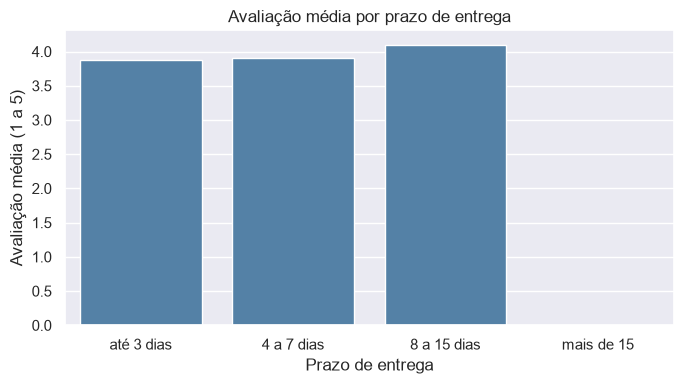

In [50]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="faixa_entrega", y="avaliacao", color="steelblue", errorbar=None)
plt.title("Avaliação média por prazo de entrega")
plt.xlabel("Prazo de entrega")
plt.ylabel("Avaliação média (1 a 5)")
plt.tight_layout()
plt.show()

Aqui a avaliação quase não muda com o prazo. Isso acontece porque, nos nossos dados **sintéticos**, as duas colunas foram sorteadas de forma independente. Em dados reais, a expectativa é que entregas mais lentas recebam notas piores. **O gráfico mostra o que está nos dados, não o que esperamos.**

## Parte 11: Funções com `apply`

Quando nenhuma função pronta resolve, você escreve a sua e aplica em cada valor (ou em cada linha) com `apply`.

### 11.1 Uma função em cada valor

In [51]:
def classificar_avaliacao(nota):
    if pd.isna(nota):
        return "sem avaliação"
    if nota >= 4:
        return "satisfeito"
    if nota == 3:
        return "neutro"
    return "insatisfeito"

df["satisfacao"] = df["avaliacao"].apply(classificar_avaliacao)
df["satisfacao"].value_counts()

satisfacao
satisfeito       263
neutro            69
insatisfeito      43
sem avaliação     25
Name: count, dtype: int64

### 11.2 Funções `lambda`
Uma `lambda` é uma função pequena, de uma linha, sem nome. Aqui ela faz o caminho inverso da Parte 2: formata o número no padrão brasileiro para exibir num relatório.

In [52]:
formatar_reais = lambda v: "R$ " + f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
df["valor_total"].head(3).apply(formatar_reais)

0    R$ 1.823,07
1      R$ 148,43
2       R$ 48,40
Name: valor_total, dtype: str

### 11.3 Uma função em cada linha: `apply(axis=1)`
Com `axis=1`, a função recebe a **linha inteira** e pode combinar várias colunas. Vamos criar uma **nota de atenção** do pedido: 1 ponto para cada sinal de problema.

In [53]:
def nota_atencao(linha):
    pontos = 0
    if linha["situacao_entrega"] in ("atrasada", "não entregue"):
        pontos += 1
    if linha["avaliacao"] <= 2:          # NaN <= 2 dá False: sem avaliação não pontua
        pontos += 1
    if linha["desconto_pct"] > 30 and not linha["pedido_atacado"]:
        pontos += 1
    return pontos

df["nota_atencao"] = df.apply(nota_atencao, axis=1)
df["nota_atencao"].value_counts().sort_index()

nota_atencao
0    316
1     81
2      3
Name: count, dtype: int64

### 11.4 Mais rápido: a versão vetorizada

### 📚 Teoria
O `apply(axis=1)` chama uma função Python **para cada linha**, o que é lento em tabelas grandes. As operações **vetorizadas** (comparar e somar colunas inteiras) rodam em código compilado do NumPy [18]. Laços com `iterrows()` são ainda mais lentos que o `apply`. **Use `apply` quando a lógica for complicada demais para colunas inteiras.**

Somar booleanos funciona porque `True` vale 1 e `False` vale 0.

In [54]:
inicio = time.perf_counter()
com_apply = df.apply(nota_atencao, axis=1)
tempo_apply = time.perf_counter() - inicio

inicio = time.perf_counter()
vetorizado = (df["situacao_entrega"].isin(["atrasada", "não entregue"]).astype(int)
              + (df["avaliacao"] <= 2).astype(int)
              + ((df["desconto_pct"] > 30) & ~df["pedido_atacado"]).astype(int))
tempo_vetorizado = time.perf_counter() - inicio

assert (com_apply == vetorizado).all(), "As duas versões deveriam dar o mesmo resultado"
print(f"apply:      {tempo_apply * 1000:7.2f} ms")
print(f"vetorizado: {tempo_vetorizado * 1000:7.2f} ms")
print(f"O vetorizado foi cerca de {tempo_apply / tempo_vetorizado:.0f} vezes mais rápido (varia a cada execução).")

apply:         5.21 ms
vetorizado:    1.07 ms
O vetorizado foi cerca de 5 vezes mais rápido (varia a cada execução).


## Parte 12: Validar e salvar

Como no Tutorial 1, terminamos **provando** que a limpeza deu certo. Cada `assert` para o notebook com erro se a regra não for cumprida.

In [55]:
assert df["preco_unitario"].notna().all() and (df["preco_unitario"] > 0).all()
assert (df["preco_unitario"] <= df.groupby("categoria")["preco_unitario"].transform("median") * 20).all(), \
    "Ainda há preço absurdo para a categoria"
assert df["tempo_entrega_dias"].dropna().between(0, 60).all(), "Prazo fora do razoável"
assert pd.api.types.is_datetime64_any_dtype(df["data_pedido"])
assert df["frete_gratis"].isin([True, False]).all()
assert df["uf"].isin(["SP", "RJ", "MG", "PR", "RS", "BA"]).all()
assert df["pedido_id"].is_unique
print("Todas as validações passaram! ✅")

Todas as validações passaram! ✅


Salvamos só as colunas úteis para as próximas análises (as colunas auxiliares de detecção ficam de fora):

In [56]:
colunas_finais = ["pedido_id", "data_pedido", "uf", "regiao", "cliente_tipo", "categoria",
                  "quantidade", "preco_unitario", "desconto_pct", "valor_total",
                  "tempo_entrega_dias", "nao_entregue", "faixa_entrega", "frete_gratis",
                  "avaliacao", "satisfacao", "pedido_atacado"]
df[colunas_finais].to_csv("pedidos_limpo.csv", index=False)
print("Arquivo 'pedidos_limpo.csv' salvo com", len(df), "linhas e", len(colunas_finais), "colunas.")

Arquivo 'pedidos_limpo.csv' salvo com 400 linhas e 17 colunas.


## Parte 13: Exercícios

Tente fazer sozinho antes de olhar as dicas. Use `df` (limpo) ou recarregue `pedidos_loja.csv` para treinar desde o começo.

1. **Z-score × MAD:** crie `pd.Series([20, 21, 22, 21, 20, 23, 22, 21, 300])`. Qual valor o Z-score aponta com |z| > 3? E o MAD com |z modificado| > 3,5? Explique a diferença usando a fórmula de Shiffler.
2. **Por grupo:** aplique a regra do IQR (k = 1,5) no `desconto_pct` **por `cliente_tipo`**. Os descontos de empresas continuam suspeitos? *(Dica: `groupby(...).transform`.)*
3. **Isolation Forest:** rode o modelo da Parte 5.2 com `contamination=0.01` e `0.10`. Quantas linhas são apontadas em cada caso? O que isso diz sobre o parâmetro?
4. **Winsorização:** winsorize `valor_total` nos percentis 5% e 95%. Quanto a média mudou? E o desvio-padrão?
5. **Amostragem:** tire uma amostra estratificada de 15% por `categoria` e confira se as proporções se mantêm.
6. **Bootstrap:** calcule o intervalo de confiança de 95% da **mediana** de `valor_total`. Ele é mais largo ou mais estreito que o da média?
7. **Ranking:** para cada `uf`, mostre os 3 pedidos de maior `valor_total`, com a posição dentro do estado.
8. **Faixas:** crie decis de `valor_total` com `qcut(q=10)` e calcule a avaliação média de cada decil.
9. **Desafio:** escreva a versão vetorizada de `classificar_avaliacao` usando `np.select` e confira com `assert` que o resultado é igual ao do `apply`.

---

### Resumo do fluxo (cole na parede! 📌)

1. **Corrigir tipos e formatos**: `str.replace`, `pd.to_numeric(errors="coerce")`, `pd.to_datetime(format=...)`, `map`
2. **Olhar**: boxplot e histograma
3. **Detectar**: IQR (`quantile`), Z-score (`stats.zscore`), MAD (mediana), por grupo (`groupby().transform`), várias colunas (`IsolationForest`)
4. **Decidir pela origem**: erro → corrigir ou `NaN`; legítimo → marcar; atrapalha um cálculo → `clip` ou `np.log1p`
5. **Transformar**: `sample`, `sort_values`, `rank`, `replace`/`map`, `np.where`/`np.select`, `cut`/`qcut`, `apply`
6. **Validar**: `assert`
7. **Guardar o original**: `df.copy()` antes de mexer

---

## Referências

**Outliers**
- [1] Hawkins, D. M. (1980). *Identification of Outliers*. Chapman and Hall.
- [9] Iglewicz, B., & Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
- [10] Shiffler, R. E. (1988). Maximum Z Scores and Outliers. *The American Statistician*, 42(1), 79–80.
- [11] Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median. *Journal of Experimental Social Psychology*, 49(4), 764–766.
- [12] Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *Proceedings of the 8th IEEE International Conference on Data Mining (ICDM)*, 413–422.

**Estatística exploratória e robusta**
- [2] Huber, P. J., & Ronchetti, E. M. (2009). *Robust Statistics* (2ª ed.). Wiley.
- [8] Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- [13] Wilcox, R. R. (2017). *Introduction to Robust Estimation and Hypothesis Testing* (4ª ed.). Academic Press.
- [14] Box, G. E. P., & Cox, D. R. (1964). An Analysis of Transformations. *Journal of the Royal Statistical Society, Series B*, 26(2), 211–252.

**Amostragem e reamostragem**
- [15] Cochran, W. G. (1977). *Sampling Techniques* (3ª ed.). Wiley.
- [16] Efron, B. (1979). Bootstrap Methods: Another Look at the Jackknife. *The Annals of Statistics*, 7(1), 1–26.
- [17] Good, P. I. (2005). *Permutation, Parametric, and Bootstrap Tests of Hypotheses* (3ª ed.). Springer.

**Formatos de dados**
- [5] NASA (1999). *Mars Climate Orbiter Mishap Investigation Board: Phase I Report*.
- [6] Ziemann, M., Eren, Y., & El-Osta, A. (2016). Gene name errors are widespread in the scientific literature. *Genome Biology*, 17, 177.
- [7] ISO 8601-1:2019. *Date and time: Representations for information interchange*. International Organization for Standardization.

**Ferramentas**
- [3] Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.
- [4] Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- [18] Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.

### 📖 Para continuar estudando (gratuitos)
- *Python for Data Analysis* (3ª ed.), de Wes McKinney, capítulos 7 (limpeza) e 10 (agrupamento): https://wesmckinney.com/book/
- Documentação do scikit-learn sobre detecção de novidades e outliers: https://scikit-learn.org/stable/modules/outlier_detection.html
- *NIST/SEMATECH e-Handbook of Statistical Methods*, seção sobre outliers: https://www.itl.nist.gov/div898/handbook/